# Figure 2 – Publication trend of the 96 included articles (2010–2026)

Reads `screening_v9_PRISMAequitycoding.xlsx` (sheet *Screening & equity*), keeps the included corpus (**Include + full text Y**), counts articles per year and dominant cluster (first label of *Thematic cluster (manual)*), and saves the figure as PNG (300 dpi) and the counts as CSV.

Put this notebook in the same folder as the Excel file, or change `XLSX` below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

XLSX = "screening_v9_PRISMAequitycoding.xlsx"
OUT_PNG = "Figure2_publication_trend.png"
OUT_CSV = "Figure2_counts_by_year_cluster.csv"

df = pd.read_excel(XLSX, sheet_name="Screening & equity", header=1)
df = df[df["ID"].notna()]
inc = df[(df["YOUR DECISION (Include/Exclude)"].astype(str).str.strip() == "Include") &
         (df["Full text retrieved (Y/N)"].astype(str).str.strip() == "Y")].copy()
print("Included articles:", len(inc))


Included articles: 96


In [2]:
inc["Year"] = pd.to_numeric(inc["Year"], errors="coerce")
missing = inc[inc["Year"].isna()][["ID", "Title (English)"]]
print("Records with missing year:")
print(missing if len(missing) else "none")

# Known fix: ID 49 (Teng, 2025). Better: correct the Excel cell, then this line does nothing.
inc.loc[inc["ID"] == 49, "Year"] = inc.loc[inc["ID"] == 49, "Year"].fillna(2025)
assert inc["Year"].notna().all(), "Fill the missing years in the Excel file first"
inc["Year"] = inc["Year"].astype(int)


Records with missing year:
none


In [3]:
inc["Cluster"] = (inc["Thematic cluster (manual)"].astype(str)
                  .str.split("/").str[0].str.strip())
order = ["Policy & governance", "Agriculture & food security", "Social equity & participation",
         "Legal & legislative framework", "Urban resilience & planning",
         "Financing mechanisms", "Science & technology support"]
assert set(inc["Cluster"]) <= set(order), set(inc["Cluster"]) - set(order)

years = list(range(2010, 2027))
tab = (pd.crosstab(inc["Year"], inc["Cluster"])
         .reindex(index=years, columns=order, fill_value=0))
tab["Total"] = tab.sum(axis=1)
tab.to_csv(OUT_CSV)
print(tab)
print("\nTotals by cluster:\n", tab[order].sum())
print("2025-2026:", tab.loc[[2025, 2026], "Total"].sum(), "| 2010-2015:", tab.loc[2010:2015, "Total"].sum())


Cluster  Policy & governance  Agriculture & food security  \
Year                                                        
2010                       1                            1   
2011                       0                            2   
2012                       3                            1   
2013                       2                            2   
2014                       0                            1   
2015                       0                            1   
2016                       1                            3   
2017                       0                            1   
2018                       1                            5   
2019                       1                            1   
2020                       3                            0   
2021                       5                            2   
2022                       2                            0   
2023                       1                            1   
2024                    

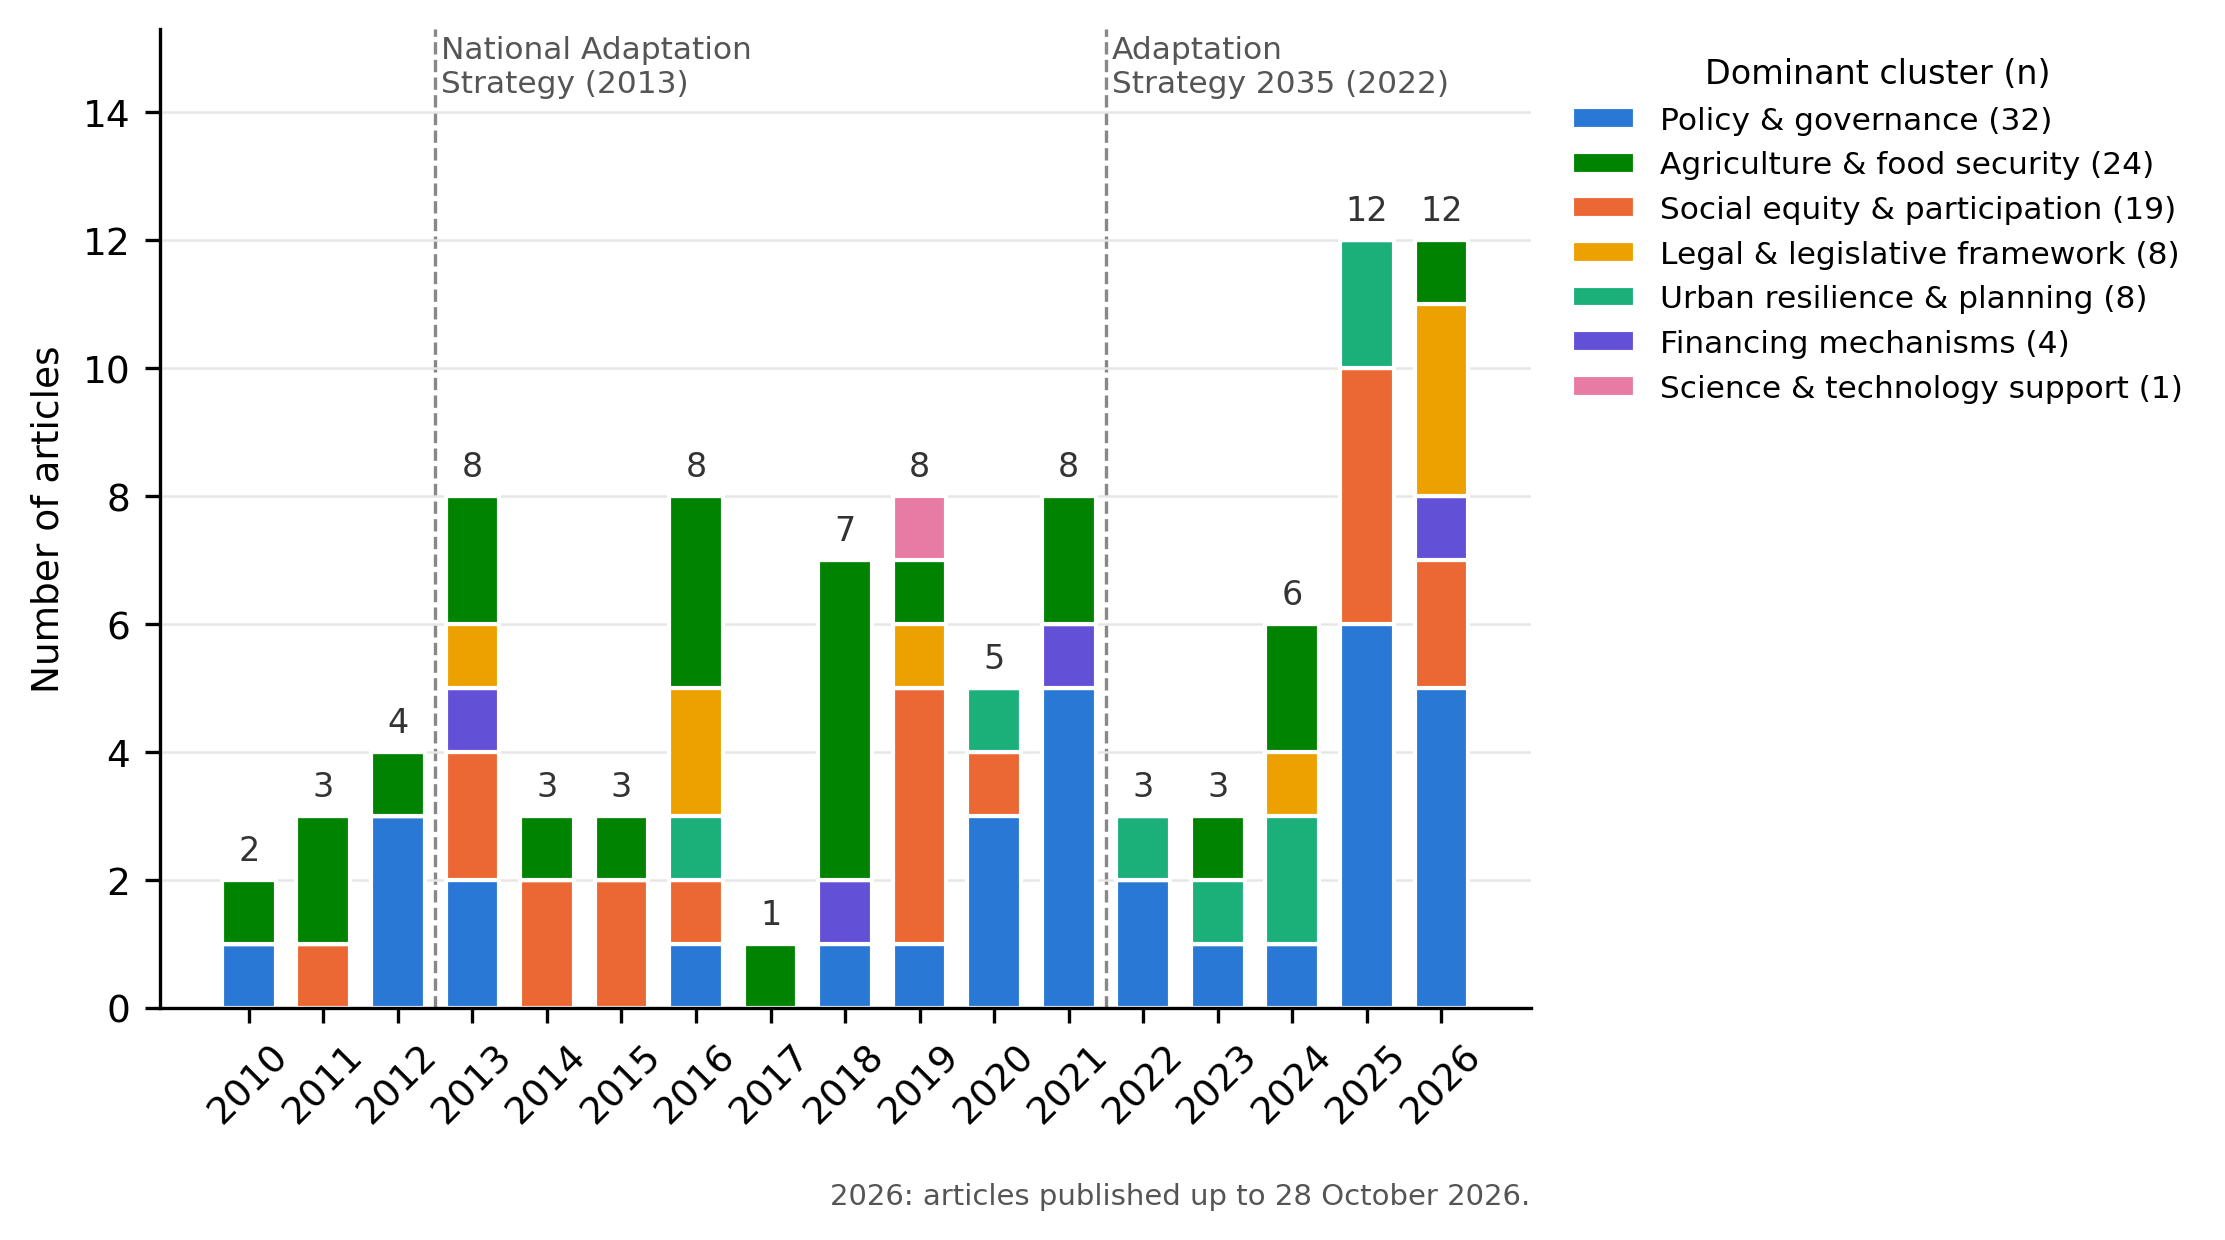

In [4]:
# Colours by meaning: equity = orange; greens = environment-related themes
colors = {
    "Policy & governance":           "#2a78d6",  # blue
    "Social equity & participation": "#eb6834",  # orange
    "Financing mechanisms":          "#6250d6",  # violet
    "Urban resilience & planning":   "#1baf7a",  # aqua-green
    "Legal & legislative framework": "#eda100",  # yellow
    "Agriculture & food security":   "#008300",  # green
    "Science & technology support":  "#e87ba4",  # pink
}
# Stacking order chosen so that neighbouring segments stay distinguishable (incl. colour-blind readers)
stack = list(colors)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})
fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=300)

bottom = pd.Series(0, index=years)
handles = {}
for c in stack:
    handles[c] = ax.bar(years, tab[c], bottom=bottom, color=colors[c], width=0.72,
                        edgecolor="white", linewidth=1.0, label=f"{c} ({int(tab[c].sum())})")
    bottom += tab[c]

for y, t in tab["Total"].items():
    if t:
        ax.text(y, t + 0.2, str(t), ha="center", va="bottom", fontsize=8, color="#333333")

top = tab["Total"].max()
for y, lab in [(2013, "National Adaptation\nStrategy (2013)"), (2022, "Adaptation\nStrategy 2035 (2022)")]:
    ax.axvline(y - 0.5, color="#888888", lw=0.8, ls="--", zorder=0)
    ax.text(y - 0.42, top + 3.2, lab, fontsize=7.5, color="#555555", va="top")

ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45)
ax.set_ylabel("Number of articles")
ax.set_ylim(0, top + 3.3)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e6", lw=0.6)
ax.set_axisbelow(True)
ax.legend([handles[c] for c in order], [f"{c} ({int(tab[c].sum())})" for c in order], title="Dominant cluster (n)", frameon=False, fontsize=7.5, title_fontsize=8,
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.text(1.0, -0.2, "2026: articles published up to 28 October 2026.", transform=ax.transAxes,
        ha="right", fontsize=7, color="#555555")
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
